# Crop type from satellite views of Fezzan farms (TME-6015 final project, code)

Notebook for the final project. Data: one 512 x 512 px Google Earth Pro view (about 580 m wide) around the GPS point of each surveyed farm; label = the single crop group the farmer reported in the 2023 Fezzan agriculture assessment.

Sections: 0 setup · 1 data and splits · 2 helpers · 3 CNN from scratch (S0-S2) · 4 transfer learning (T1-T5) · 5 test-set evaluation · 6 robustness (held-out areas) · 7 downstream use (survey check) · 8 save models.

Rule used for every experiment: one change per model; a change is kept only if the pooled out-of-fold macro-F1 on the development set goes up.

## 0. Setup

In [1]:
import os, time, json, math, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score, log_loss)
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)
DATA = "data"                     # contains chips/ and chips_index.csv
FAST = os.environ.get("FAST") == "1"   # quick smoke test on a small subset
OUT = "outputs_smoke" if FAST else "outputs"; os.makedirs(OUT, exist_ok=True)
WEIGHTS_DIR = "weights"           # optional local ImageNet weights; otherwise Keras downloads them
CLASSES = ["alfalfa", "cereals", "palm", "palm_orchard"]; N = len(CLASSES)
COLORS = ["#2b6cb0", "#d98a00", "#1f7a5a", "#b03a3a"]
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795401051.136917    1834 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795401052.212015    1834 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | GPU: []


## 1. Data and splits

In [2]:
idx = pd.read_csv(f"{DATA}/chips_index.csv")
print("all images:", len(idx), "| farms:", idx.farm.nunique())
print("images per year:", idx.year.value_counts().sort_index().to_dict())

idx = idx[idx.year >= 2021]                                             # keep images close to the 2023 survey
conflict = set(pd.read_csv(f"{DATA}/conflicting_farms.csv").farm)       # same view, different reported crop
idx = idx[~idx.farm.isin(conflict)].reset_index(drop=True)
if FAST: idx = idx[idx.farm.isin(idx.drop_duplicates("farm").groupby("label").head(70).farm)].reset_index(drop=True)
idx["y"] = idx.label.map(CLASSES.index)
print("kept images:", len(idx), "| farms:", idx.farm.nunique(), "| spatial clusters:", idx.cluster.nunique(), "| areas:", idx.area.nunique())
print("images per farm:", idx.groupby("farm").size().value_counts().sort_index().to_dict())
display(pd.crosstab(idx.label, idx.year, margins=True))

all images: 2132 | farms: 1162
images per year: {2012.0: 9, 2013.0: 3, 2016.0: 4, 2018.0: 223, 2019.0: 7, 2020.0: 35, 2021.0: 486, 2022.0: 331, 2023.0: 978, 2024.0: 1, 2025.0: 51}
kept images: 1839 | farms: 1122 | spatial clusters: 365 | areas: 66
images per farm: {1: 450, 2: 627, 3: 45}


year,2021.0,2022.0,2023.0,2024.0,2025.0,All
label,,,,,,
alfalfa,52,74,284,0,15,425
cereals,93,116,256,0,15,480
palm,257,73,295,1,10,636
palm_orchard,82,68,139,0,9,298
All,484,331,974,1,49,1839


In [3]:
# Test set = whole spatial clusters (farms within 600 m of each other stay together), about 20% of farms.
farms = idx.drop_duplicates("farm")[["farm", "y", "cluster", "area"]].reset_index(drop=True)
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_i, test_i = next(sgk.split(farms, farms.y, farms.cluster))
idx["split"] = np.where(idx.farm.isin(set(farms.farm[test_i])), "test", "dev")

# Development set: 5 folds, again grouped by spatial cluster
dev_f = farms.iloc[dev_i].reset_index(drop=True); fold_of = {}
for k, (_, va) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(dev_f, dev_f.y, dev_f.cluster)):
    fold_of.update({f: k for f in dev_f.farm[va]})
idx["fold"] = idx.farm.map(fold_of).fillna(-1).astype(int)

assert not set(idx.cluster[idx.split == "test"]) & set(idx.cluster[idx.split == "dev"])
for k in range(5):
    assert not set(idx.cluster[idx.fold == k]) & set(idx.cluster[(idx.fold != k) & (idx.split == "dev")])

DEV = np.where(idx.split == "dev")[0]; TEST = np.where(idx.split == "test")[0]; y = idx.y.to_numpy(dtype=np.int64)
tab = pd.crosstab(idx.label, idx.fold.map(lambda k: f"fold {k + 1}" if k >= 0 else "test"))
tab["farms"] = idx.drop_duplicates("farm").label.value_counts()
display(tab)
maj = np.bincount(y[DEV]).argmax()
print(f"baseline (always '{CLASSES[maj]}'): dev accuracy {np.mean(y[DEV] == maj):.3f} | test accuracy {np.mean(y[TEST] == maj):.3f} | macro-F1 {f1_score(y[TEST], np.full(len(TEST), maj), average='macro'):.3f}")

fold,fold 1,fold 2,fold 3,fold 4,fold 5,test,farms
label,,,,,,,
alfalfa,66,65,60,81,58,95,297
cereals,66,88,80,81,74,91,291
palm,103,97,130,92,96,118,352
palm_orchard,49,48,49,49,51,52,182


baseline (always 'palm'): dev accuracy 0.349 | test accuracy 0.331 | macro-F1 0.124


{580: (1839, 224, 224, 3), 290: (1839, 224, 224, 3)} 20 s


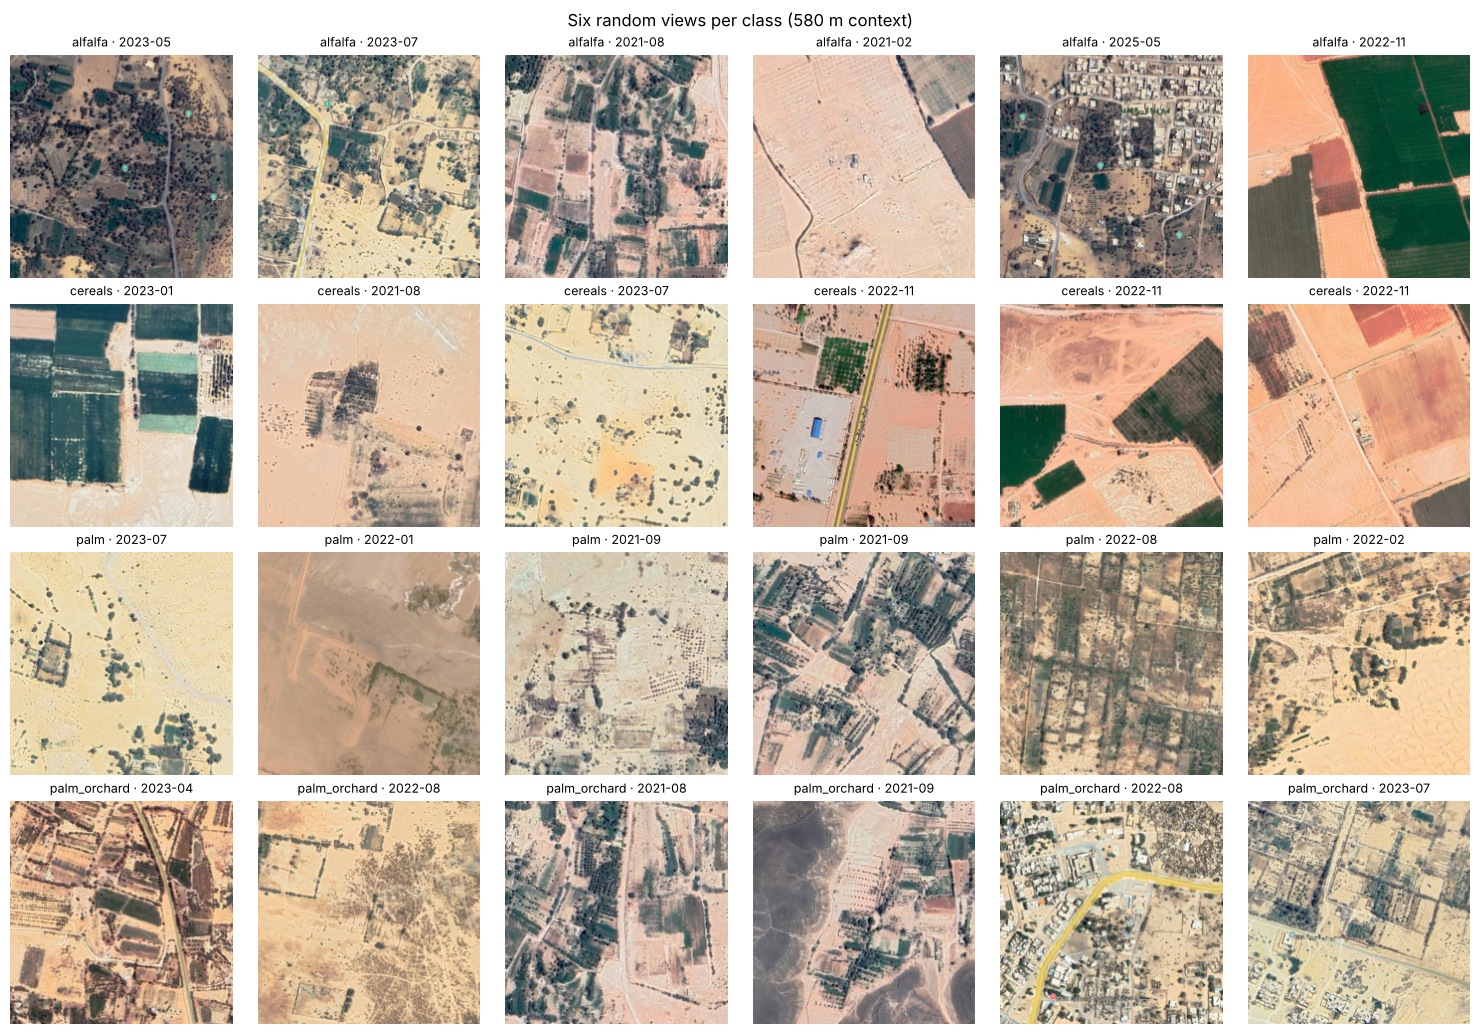

In [4]:
# Load every image once, for two context sizes: 580 m (whole chip) and 290 m (centre half)
def load(path, ctx, px):
    im = Image.open(f"{DATA}/{path}").convert("RGB")
    if ctx == 290: im = im.crop((128, 128, 384, 384))
    return np.asarray(im.resize((px, px), Image.BILINEAR), dtype=np.uint8)
t = time.time()
X224 = {c: np.stack([load(p, c, 224) for p in idx.image]) for c in (580, 290)}
X128 = {c: np.stack([load(p, c, 128) for p in idx.image]) for c in (580, 290)}
print({k: v.shape for k, v in X224.items()}, f"{time.time() - t:.0f} s")

fig, ax = plt.subplots(4, 6, figsize=(15, 10.5))
for r, c in enumerate(CLASSES):
    for j, i in enumerate(idx[idx.label == c].sample(6, random_state=1).index):
        ax[r, j].imshow(X224[580][i]); ax[r, j].set_title(f"{c} · {idx.img_date[i][:7]}", fontsize=9); ax[r, j].axis("off")
plt.suptitle("Six random views per class (580 m context)"); plt.tight_layout(); plt.savefig(f"{OUT}/samples.png", dpi=110); plt.show()

## 2. Helpers

In [5]:
RESULTS, OOF, HIST = [], {}, {}

def per_class_recall(yt, yp): return [float(np.mean(yp[yt == c] == c)) if np.any(yt == c) else np.nan for c in range(N)]

def farm_level(rows, P):
    df = pd.DataFrame(P, columns=CLASSES); df["farm"] = idx.farm.values[rows]; df["y"] = y[rows]
    g = df.groupby("farm").mean(numeric_only=True)
    return g.y.astype(int).values, g[CLASSES].values

def score(name, change, P, extra=None):
    yt = y[DEV]; yp = P.argmax(1); fy, fp = farm_level(DEV, P)
    row = {"model": name, "change": change, "val acc": accuracy_score(yt, yp), "val macro-F1": f1_score(yt, yp, average="macro"),
           "farm macro-F1": f1_score(fy, fp.argmax(1), average="macro"), "val log loss": log_loss(yt, np.clip(P, 1e-7, 1), labels=range(N))}
    row.update({f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, yp))}); row.update(extra or {})
    RESULTS.append(row); OOF[name] = P
    print(f"{name}: {change}\n  val acc {row['val acc']:.3f} | macro-F1 {row['val macro-F1']:.3f} | farm-level macro-F1 {row['farm macro-F1']:.3f} | log loss {row['val log loss']:.3f}")
    print("  recall per class:", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(yt, yp))})
    return row

def table(names=None):
    t = pd.DataFrame(RESULTS).set_index("model")
    return (t.loc[names] if names else t).round(3)

def better(new, old): return new["val macro-F1"] > old["val macro-F1"]

class PerClass(keras.callbacks.Callback):
    """Validation recall of each class after every epoch (fold 1 only)."""
    def __init__(self, Xv, yv): super().__init__(); self.Xv, self.yv, self.v = Xv, yv, []
    def on_epoch_end(self, epoch, logs=None):
        self.v.append(per_class_recall(self.yv, self.model.predict(self.Xv, verbose=0).argmax(1)))

def plot_curves(name):
    h = HIST[name]; e = range(1, len(h["loss"]) + 1); best = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    for a, m in zip(ax[:2], ["accuracy", "loss"]):
        a.plot(e, h[m], label="train"); a.plot(e, h["val_" + m], label="validation"); a.axvline(best, ls=":", c="gray"); a.set_title(f"{name}: {m} (fold 1)"); a.set_xlabel("epoch"); a.legend()
    pc = np.array(h["per_class"])
    for c in range(N): ax[2].plot(e, pc[:, c], c=COLORS[c], label=CLASSES[c])
    ax[2].axvline(best, ls=":", c="gray"); ax[2].set_ylim(0, 1); ax[2].set_title("validation recall per class (fold 1)"); ax[2].set_xlabel("epoch"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/curves_{name}.png", dpi=110); plt.show()

## 3. CNN from scratch (128 px input)

In [6]:
def make_ds(X, yy, train, bs=32):
    ds = tf.data.Dataset.from_tensor_slices((X, yy))
    if train:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

def rot_flip(x):
    """A satellite view has no 'up': any 90-degree rotation or flip is still a valid view of the same farm."""
    x = tf.image.rot90(x, tf.random.uniform([], 0, 4, dtype=tf.int32))
    return tf.image.random_flip_left_right(x)

class RotFlip(layers.Layer):
    def call(self, x, training=None):
        return tf.map_fn(rot_flip, x) if training else x

def build_cnn(filters=(32, 64, 128), augment=False, dropout=0.0, px=128):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((px, px, 3)); x = RotFlip()(inp) if augment else inp
    x = layers.Rescaling(1 / 255)(x)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x); x = layers.Activation("relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout: x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))

def run_cnn(name, change, ctx=580, max_epochs=30, patience=6, lr=1e-3, **kw):
    max_epochs = 2 if FAST else max_epochs; X = X128[ctx]; P = np.zeros((len(DEV), N)); epochs = []; t = time.time()
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        m = build_cnn(**kw); m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(X[va], y[va]); cb.append(pcb)
        h = m.fit(make_ds(X[tr], y[tr], True), validation_data=make_ds(X[va], y[va], False), epochs=max_epochs, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = m.predict(X[va], verbose=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "time (s)": round(time.time() - t)})
    plot_curves(name); return row

S0: 3 conv blocks (32-64-128) + batch norm, 580 m context, Adam 0.001
  val acc 0.443 | macro-F1 0.327 | farm-level macro-F1 0.321 | log loss 1.284
  recall per class: {'alfalfa': 0.1, 'cereals': 0.6, 'palm': 0.73, 'palm_orchard': 0.04}


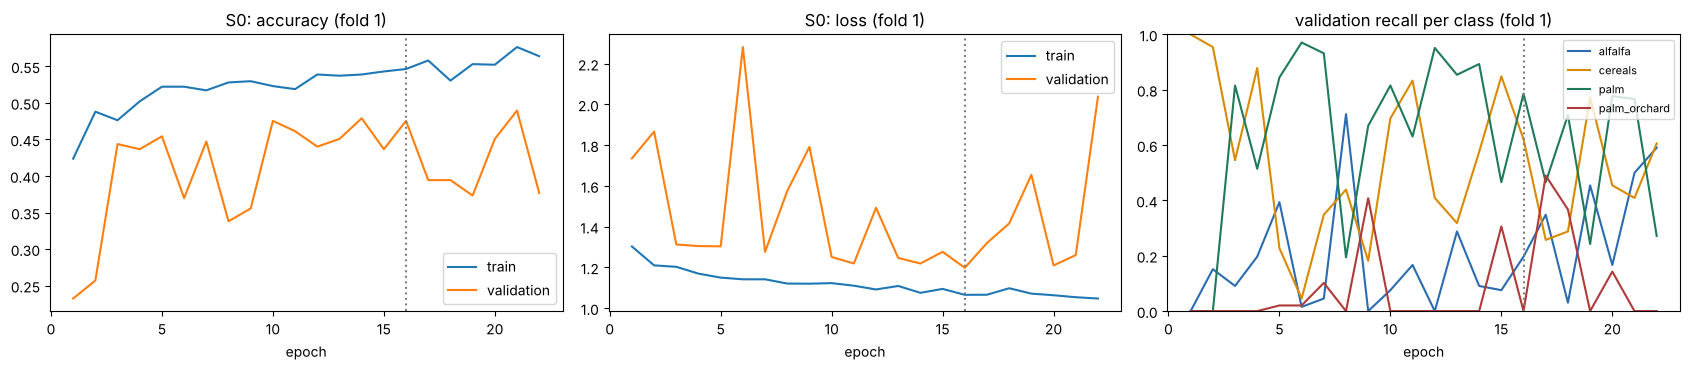

In [7]:
cnn_cfg = dict(filters=(32, 64, 128), augment=False, dropout=0.0)
s0 = run_cnn("S0", "3 conv blocks (32-64-128) + batch norm, 580 m context, Adam 0.001", **cnn_cfg); best_s, best_s_row = "S0", s0

S1: S0 + random 90-degree rotations and flips
  val acc 0.435 | macro-F1 0.365 | farm-level macro-F1 0.362 | log loss 1.255
  recall per class: {'alfalfa': 0.19, 'cereals': 0.53, 'palm': 0.66, 'palm_orchard': 0.13}


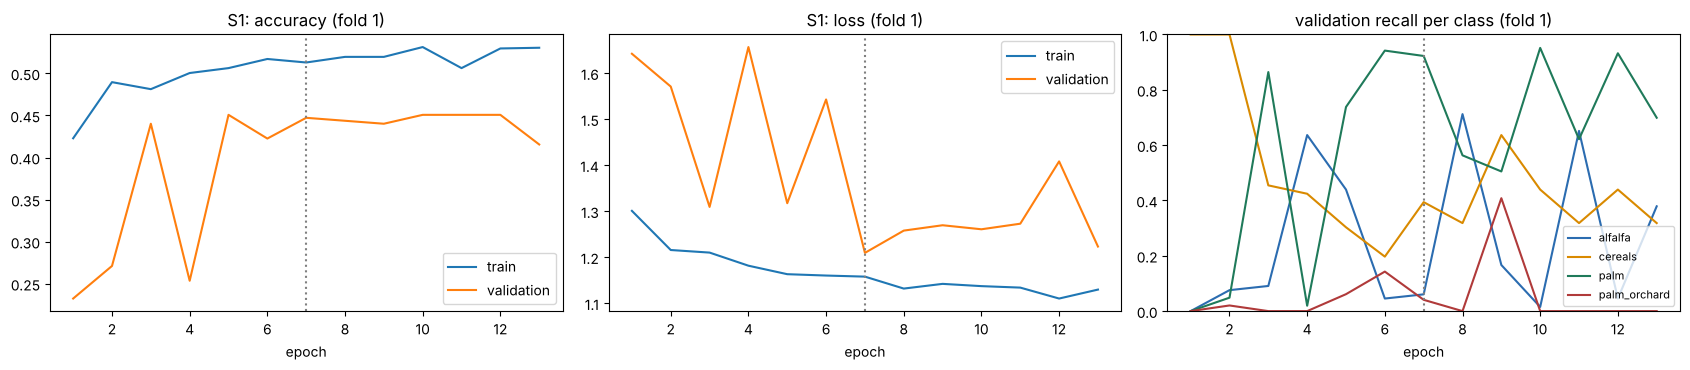

kept: S1


In [8]:
s1 = run_cnn("S1", "S0 + random 90-degree rotations and flips", **{**cnn_cfg, "augment": True})
if better(s1, best_s_row): cnn_cfg["augment"] = True; best_s, best_s_row = "S1", s1
print("kept:", best_s)

S2: S1 + fourth conv block (256 filters)
  val acc 0.456 | macro-F1 0.358 | farm-level macro-F1 0.367 | log loss 1.248
  recall per class: {'alfalfa': 0.25, 'cereals': 0.43, 'palm': 0.8, 'palm_orchard': 0.04}


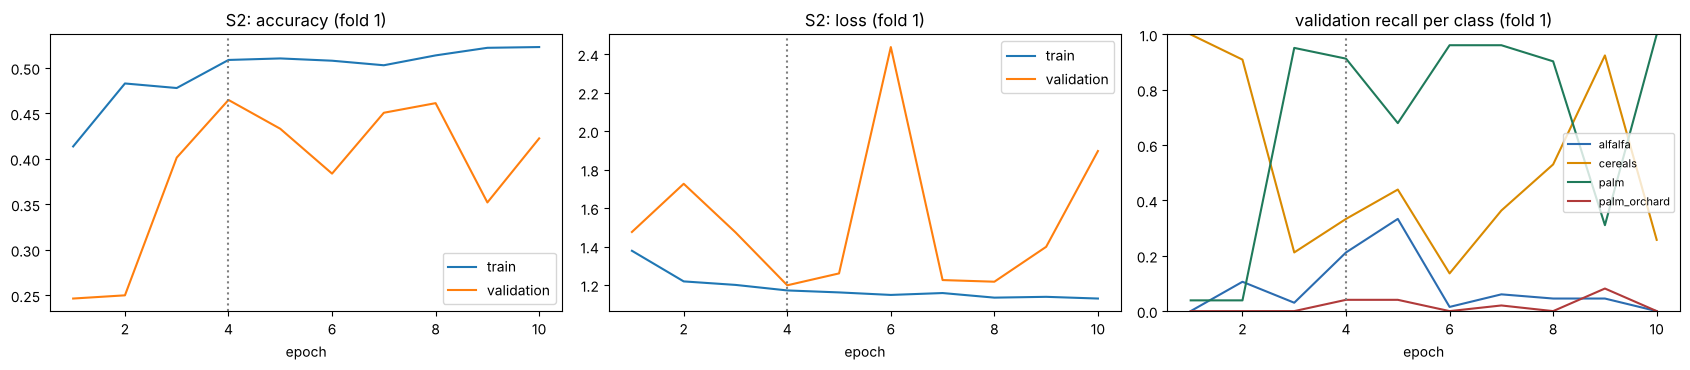

kept: S1


In [9]:
s2 = run_cnn("S2", f"{best_s} + fourth conv block (256 filters)", **{**cnn_cfg, "filters": (32, 64, 128, 256)})
if better(s2, best_s_row): cnn_cfg["filters"] = (32, 64, 128, 256); best_s, best_s_row = "S2", s2
print("kept:", best_s)

S3: S1 + dropout 0.3 before the output layer
  val acc 0.459 | macro-F1 0.359 | farm-level macro-F1 0.358 | log loss 1.283
  recall per class: {'alfalfa': 0.22, 'cereals': 0.56, 'palm': 0.74, 'palm_orchard': 0.03}


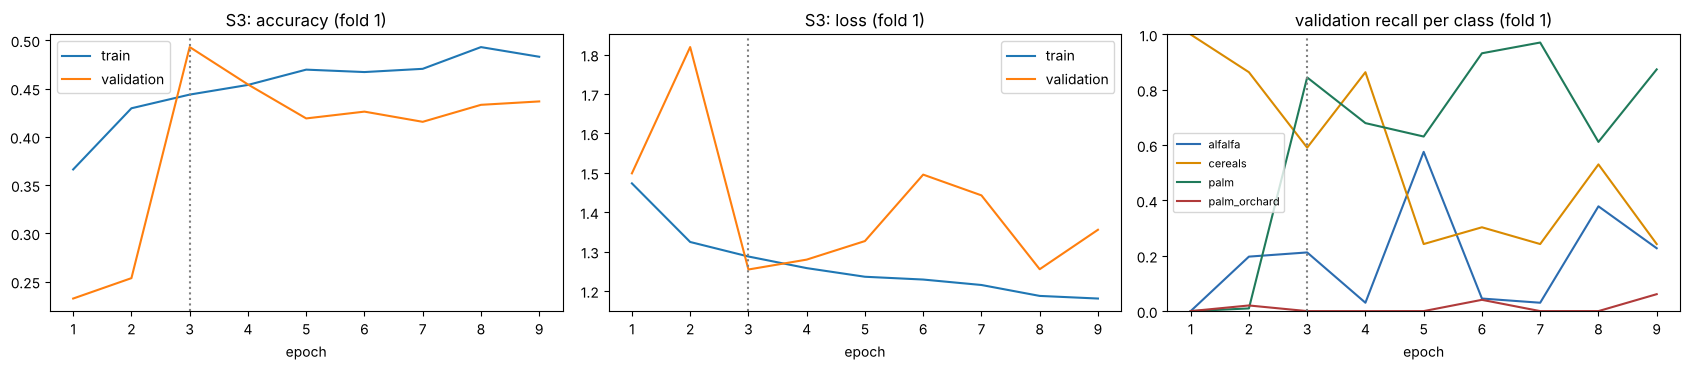

final CNN from scratch: S1 {'filters': (32, 64, 128), 'augment': True, 'dropout': 0.0}


,change,val acc,val macro-F1,farm macro-F1,val log loss,recall alfalfa,recall cereals,recall palm,recall palm_orchard,weights,best epochs,time (s)
model,,,,,,,,,,,,
S0,"3 conv blocks (32-64-128) + batch norm, 580 m ...",0.443,0.327,0.321,1.284,0.103,0.604,0.730,0.041,94436,"[16, 2, 6, 2, 3]",804
S1,S0 + random 90-degree rotations and flips,0.435,0.365,0.362,1.255,0.194,0.535,0.660,0.126,94436,"[7, 7, 5, 11, 10]",1043
S2,S1 + fourth conv block (256 filters),0.456,0.358,0.367,1.248,0.252,0.427,0.803,0.045,390884,"[4, 4, 5, 6, 5]",983
S3,S1 + dropout 0.3 before the output layer,0.459,0.359,0.358,1.283,0.218,0.558,0.743,0.028,94436,"[3, 2, 5, 9, 3]",736


In [10]:
s3 = run_cnn("S3", f"{best_s} + dropout 0.3 before the output layer", **{**cnn_cfg, "dropout": 0.3})
if better(s3, best_s_row): cnn_cfg["dropout"] = 0.3; best_s, best_s_row = "S3", s3
print("final CNN from scratch:", best_s, cnn_cfg); display(table(["S0", "S1", "S2", "S3"]))

## 4. Transfer learning (frozen ImageNet backbones)

In [11]:
BACKBONES = {
    "resnet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input, "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"),
    "densenet121": (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input, "densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5"),
}
def backbone(name):
    fn, pre, wfile = BACKBONES[name]; local = os.path.join(WEIGHTS_DIR, wfile)
    m = fn(include_top=False, weights=None if os.path.exists(local) else "imagenet", input_shape=(224, 224, 3), pooling="avg")
    if os.path.exists(local): m.load_weights(local)
    return m, pre

def features(name, ctx):
    """Pooled features of every image in its 4 rotations -> array (4, n_images, d). Cached on disk."""
    path = f"{OUT}/features_{name}_{ctx}.npy"
    if os.path.exists(path): return np.load(path)
    m, pre = backbone(name); t = time.time()
    F = np.stack([m.predict(pre(np.rot90(X224[ctx], r, axes=(1, 2)).astype("float32")), batch_size=32, verbose=0) for r in range(4)])
    np.save(path, F); print(f"features {name} {ctx} m: {F.shape} in {time.time() - t:.0f} s"); return F

def lr_head(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))

def run_lr(name, change, F, rotations=False):
    P = np.zeros((len(DEV), N)); t = time.time()
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        R = range(4) if rotations else range(1)
        clf = lr_head().fit(np.concatenate([F[r][tr] for r in R]), np.tile(y[tr], len(R)))
        P[np.searchsorted(DEV, va)] = np.mean([clf.predict_proba(F[r][va]) for r in R], axis=0)
    return score(name, change, P, {"weights": (F.shape[2] + 1) * N, "time (s)": round(time.time() - t)})

In [12]:
tl = dict(backbone="resnet50", ctx=580, rotations=False)
t1 = run_lr("T1", "ResNet50 frozen, 580 m, logistic regression head", features("resnet50", 580)); best_t, best_t_row = "T1", t1

features resnet50 580 m: (4, 1839, 2048) in 331 s


T1: ResNet50 frozen, 580 m, logistic regression head
  val acc 0.434 | macro-F1 0.405 | farm-level macro-F1 0.438 | log loss 1.837
  recall per class: {'alfalfa': 0.34, 'cereals': 0.49, 'palm': 0.54, 'palm_orchard': 0.25}


In [13]:
t2 = run_lr("T2", "T1 + rotation invariance (train on 4 rotations, average 4 rotations)", features("resnet50", 580), rotations=True)
if better(t2, best_t_row): tl["rotations"] = True; best_t, best_t_row = "T2", t2
print("kept:", best_t)

T2: T1 + rotation invariance (train on 4 rotations, average 4 rotations)
  val acc 0.415 | macro-F1 0.382 | farm-level macro-F1 0.406 | log loss 1.727
  recall per class: {'alfalfa': 0.34, 'cereals': 0.44, 'palm': 0.54, 'palm_orchard': 0.2}
kept: T1


In [14]:
t3 = run_lr("T3", f"{best_t} with 290 m context (centre half of the view)", features("resnet50", 290), rotations=tl["rotations"])
if better(t3, best_t_row): tl["ctx"] = 290; best_t, best_t_row = "T3", t3
print("kept:", best_t)

features resnet50 290 m: (4, 1839, 2048) in 337 s


T3: T1 with 290 m context (centre half of the view)
  val acc 0.432 | macro-F1 0.397 | farm-level macro-F1 0.426 | log loss 1.977
  recall per class: {'alfalfa': 0.32, 'cereals': 0.39, 'palm': 0.62, 'palm_orchard': 0.27}
kept: T1


In [15]:
t4 = run_lr("T4", f"{best_t} with DenseNet121 in place of ResNet50", features("densenet121", tl["ctx"]), rotations=tl["rotations"])
if better(t4, best_t_row): tl["backbone"] = "densenet121"; best_t, best_t_row = "T4", t4
print("kept:", best_t, tl)

features densenet121 580 m: (4, 1839, 1024) in 331 s


T4: T1 with DenseNet121 in place of ResNet50
  val acc 0.444 | macro-F1 0.406 | farm-level macro-F1 0.424 | log loss 1.781
  recall per class: {'alfalfa': 0.35, 'cereals': 0.51, 'palm': 0.58, 'palm_orchard': 0.19}
kept: T4 {'backbone': 'densenet121', 'ctx': 580, 'rotations': False}


T5: T4 with a dense head (256 units, dropout 0.4) in place of logistic regression
  val acc 0.469 | macro-F1 0.430 | farm-level macro-F1 0.442 | log loss 1.408
  recall per class: {'alfalfa': 0.43, 'cereals': 0.46, 'palm': 0.62, 'palm_orchard': 0.22}


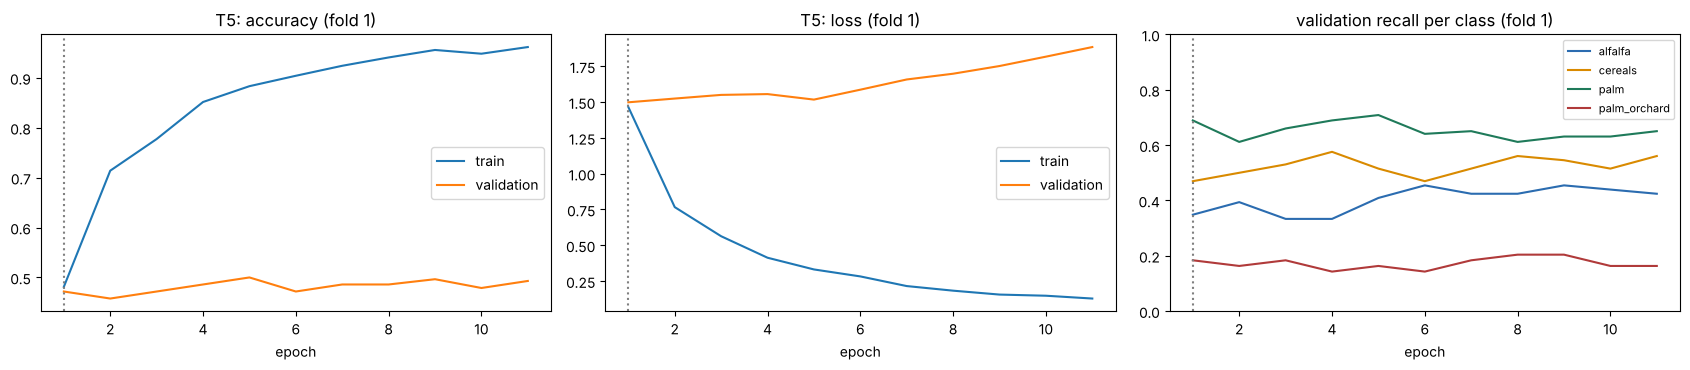

final transfer model: T5 {'backbone': 'densenet121', 'ctx': 580, 'rotations': False, 'head': 'dense'}


,change,val acc,val macro-F1,farm macro-F1,val log loss,recall alfalfa,recall cereals,recall palm,recall palm_orchard,weights,best epochs,time (s)
model,,,,,,,,,,,,
T1,"ResNet50 frozen, 580 m, logistic regression head",0.434,0.405,0.438,1.837,0.342,0.486,0.541,0.252,8196,NaN,2
T2,T1 + rotation invariance (train on 4 rotations...,0.415,0.382,0.406,1.727,0.342,0.442,0.541,0.203,8196,NaN,6
T3,T1 with 290 m context (centre half of the view),0.432,0.397,0.426,1.977,0.315,0.391,0.616,0.268,8196,NaN,1
T4,T1 with DenseNet121 in place of ResNet50,0.444,0.406,0.424,1.781,0.345,0.509,0.579,0.187,4100,NaN,1
T5,"T4 with a dense head (256 units, dropout 0.4) ...",0.469,0.430,0.442,1.408,0.430,0.455,0.624,0.215,263428,"[1, 1, 2, 1, 3]",14


In [16]:
# T5: small trained network head on the same frozen features (gives training curves)
def dense_head(d):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((d,)); x = layers.Dense(256, activation="relu")(inp); x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))

def run_dense(name, change, F, rotations, max_epochs=100, patience=10):
    max_epochs = 2 if FAST else max_epochs
    P = np.zeros((len(DEV), N)); t = time.time(); epochs = []
    mu, sd = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6; Fz = (F - mu) / sd
    R = range(4) if rotations else range(1)
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        m = dense_head(F.shape[2]); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(Fz[0][va], y[va]); cb.append(pcb)
        h = m.fit(np.concatenate([Fz[r][tr] for r in R]), np.tile(y[tr], len(R)), validation_data=(Fz[0][va], y[va]),
                  epochs=max_epochs, batch_size=64, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = np.mean([m.predict(Fz[r][va], verbose=0) for r in R], axis=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "time (s)": round(time.time() - t)})
    plot_curves(name); return row

best_lr = best_t   # best model with the logistic head (used again in section 6)
t5 = run_dense("T5", f"{best_t} with a dense head (256 units, dropout 0.4) in place of logistic regression", features(tl["backbone"], tl["ctx"]), tl["rotations"])
if better(t5, best_t_row): tl["head"] = "dense"; best_t, best_t_row = "T5", t5
else: tl["head"] = "logistic"
print("final transfer model:", best_t, tl)
display(table(["T1", "T2", "T3", "T4", "T5"]))

In [17]:
display(table())
table().to_csv(f"{OUT}/experiments.csv")

,change,val acc,val macro-F1,farm macro-F1,val log loss,recall alfalfa,recall cereals,recall palm,recall palm_orchard,weights,best epochs,time (s)
model,,,,,,,,,,,,
S0,"3 conv blocks (32-64-128) + batch norm, 580 m ...",0.443,0.327,0.321,1.284,0.103,0.604,0.730,0.041,94436,"[16, 2, 6, 2, 3]",804
S1,S0 + random 90-degree rotations and flips,0.435,0.365,0.362,1.255,0.194,0.535,0.660,0.126,94436,"[7, 7, 5, 11, 10]",1043
S2,S1 + fourth conv block (256 filters),0.456,0.358,0.367,1.248,0.252,0.427,0.803,0.045,390884,"[4, 4, 5, 6, 5]",983
S3,S1 + dropout 0.3 before the output layer,0.459,0.359,0.358,1.283,0.218,0.558,0.743,0.028,94436,"[3, 2, 5, 9, 3]",736
T1,"ResNet50 frozen, 580 m, logistic regression head",0.434,0.405,0.438,1.837,0.342,0.486,0.541,0.252,8196,NaN,2
T2,T1 + rotation invariance (train on 4 rotations...,0.415,0.382,0.406,1.727,0.342,0.442,0.541,0.203,8196,NaN,6
T3,T1 with 290 m context (centre half of the view),0.432,0.397,0.426,1.977,0.315,0.391,0.616,0.268,8196,NaN,1
T4,T1 with DenseNet121 in place of ResNet50,0.444,0.406,0.424,1.781,0.345,0.509,0.579,0.187,4100,NaN,1
T5,"T4 with a dense head (256 units, dropout 0.4) ...",0.469,0.430,0.442,1.408,0.430,0.455,0.624,0.215,263428,"[1, 1, 2, 1, 3]",14


## 5. Test set: final models trained on all development farms

In [18]:
# CNN from scratch: retrain on all development images for the median best epoch from cross-validation
ep = int(np.median(RESULTS[[r["model"] for r in RESULTS].index(best_s)]["best epochs"]))
cnn = build_cnn(**cnn_cfg); cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.fit(make_ds(X128[580][DEV], y[DEV], True), epochs=ep, verbose=0)
P_cnn = cnn.predict(X128[580][TEST], verbose=0)

# Transfer model
F_best = features(tl["backbone"], tl["ctx"]); R = range(4) if tl["rotations"] else range(1)
if tl["head"] == "logistic":
    head = lr_head().fit(np.concatenate([F_best[r][DEV] for r in R]), np.tile(y[DEV], len(R)))
    P_tl = np.mean([head.predict_proba(F_best[r][TEST]) for r in R], axis=0)
else:
    mu, sd = F_best[0][DEV].mean(0), F_best[0][DEV].std(0) + 1e-6; Fz = (F_best - mu) / sd
    ep_t = int(np.median(RESULTS[[r["model"] for r in RESULTS].index(best_t)]["best epochs"]))
    head = dense_head(F_best.shape[2]); head.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    head.fit(np.concatenate([Fz[r][DEV] for r in R]), np.tile(y[DEV], len(R)), epochs=ep_t, batch_size=64, verbose=0)
    P_tl = np.mean([head.predict(Fz[r][TEST], verbose=0) for r in R], axis=0)

yt = y[TEST]; maj_p = np.zeros((len(TEST), N)); maj_p[:, maj] = 1
summary = {}
for nm, P in [("baseline", maj_p), (f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]:
    fy, fp = farm_level(TEST, P)
    summary[nm] = {"test images": len(TEST), "accuracy": accuracy_score(yt, P.argmax(1)), "macro-F1": f1_score(yt, P.argmax(1), average="macro"),
                   "farm-level accuracy": accuracy_score(fy, fp.argmax(1)), "farm-level macro-F1": f1_score(fy, fp.argmax(1), average="macro"),
                   "macro AUC (one-vs-rest)": roc_auc_score(yt, P, multi_class="ovr", average="macro") if nm != "baseline" else 0.5,
                   **{f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, P.argmax(1)))}}
summary = pd.DataFrame(summary).round(3); display(summary); summary.to_csv(f"{OUT}/test_summary.csv")
for nm, P in [(f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]:
    print(nm); print(classification_report(yt, P.argmax(1), target_names=CLASSES, digits=3))

,baseline,CNN from scratch (S1),transfer (T5)
test images,356.000,356.000,356.000
accuracy,0.331,0.421,0.396
macro-F1,0.124,0.283,0.351
farm-level accuracy,0.278,0.361,0.365
farm-level macro-F1,0.109,0.260,0.346
macro AUC (one-vs-rest),0.500,0.537,0.628
recall alfalfa,0.000,0.000,0.147
recall cereals,0.000,0.396,0.571
recall palm,1.000,0.949,0.568
recall palm_orchard,0.000,0.038,0.154


CNN from scratch (S1)
              precision    recall  f1-score   support

     alfalfa      0.000     0.000     0.000        95
     cereals      0.837     0.396     0.537        91
        palm      0.368     0.949     0.531       118
palm_orchard      0.222     0.038     0.066        52

    accuracy                          0.421       356
   macro avg      0.357     0.346     0.283       356
weighted avg      0.369     0.421     0.323       356

transfer (T5)
              precision    recall  f1-score   support

     alfalfa      0.298     0.147     0.197        95
     cereals      0.605     0.571     0.588        91
        palm      0.401     0.568     0.470       118
palm_orchard      0.143     0.154     0.148        52

    accuracy                          0.396       356
   macro avg      0.362     0.360     0.351       356
weighted avg      0.388     0.396     0.380       356



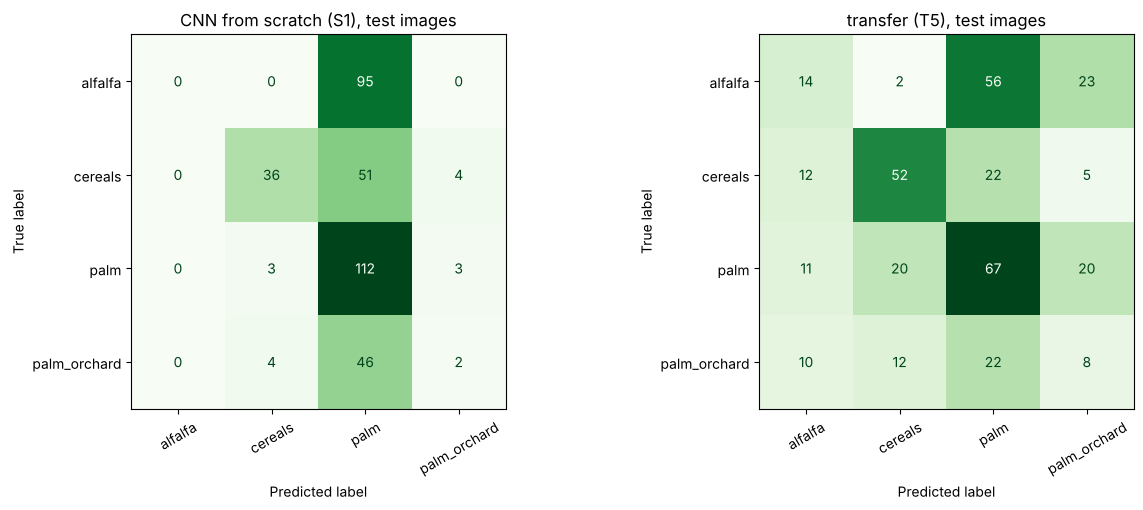

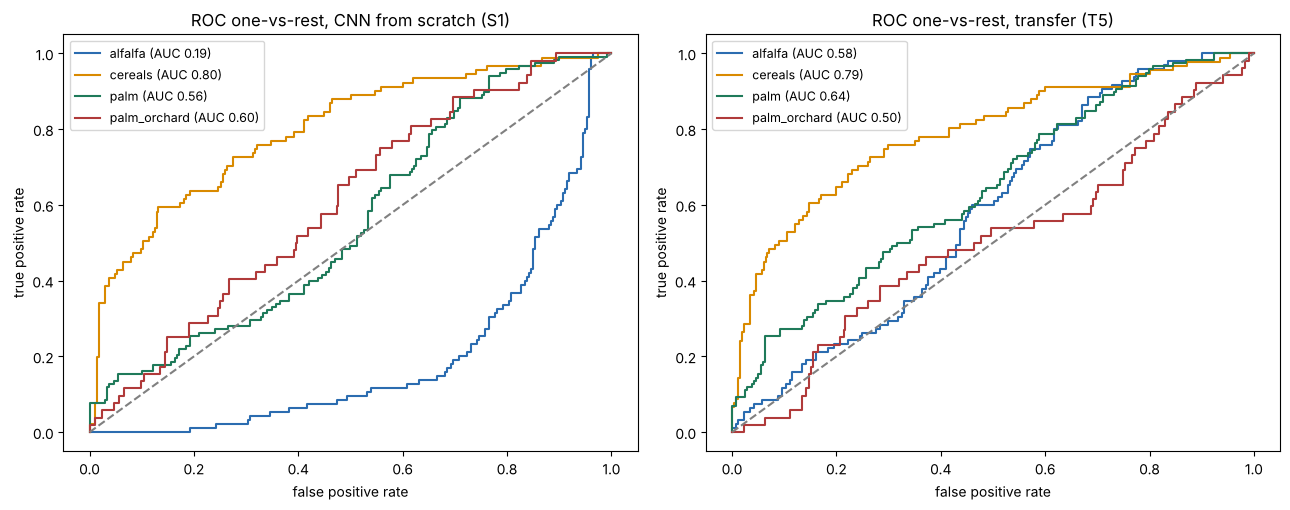

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a, (nm, P) in zip(ax, [(f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, P.argmax(1), labels=range(N)), display_labels=CLASSES).plot(ax=a, cmap="Greens", colorbar=False)
    a.set_title(f"{nm}, test images"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT}/test_confusion.png", dpi=110); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a, (nm, P) in zip(ax, [(f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]):
    for c in range(N):
        fpr, tpr, _ = roc_curve(yt == c, P[:, c]); a.plot(fpr, tpr, c=COLORS[c], label=f"{CLASSES[c]} (AUC {roc_auc_score(yt == c, P[:, c]):.2f})")
    a.plot([0, 1], [0, 1], ls="--", c="gray"); a.set_title(f"ROC one-vs-rest, {nm}"); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate"); a.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/test_roc.png", dpi=110); plt.show()

In [20]:
# Bootstrap over test farms: difference in farm-level macro-F1 (transfer minus scratch)
fy, f_cnn = farm_level(TEST, P_cnn); _, f_tl = farm_level(TEST, P_tl); rng = np.random.default_rng(SEED); d = []
for _ in range(3000):
    s = rng.integers(0, len(fy), len(fy))
    d.append(f1_score(fy[s], f_tl[s].argmax(1), average="macro") - f1_score(fy[s], f_cnn[s].argmax(1), average="macro"))
d = np.array(d); print(f"test farms: {len(fy)} | macro-F1 difference {np.mean(d):+.3f}, 95% interval {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}, transfer ahead in {np.mean(d > 0):.1%} of resamples")

test farms: 252 | macro-F1 difference +0.084, 95% interval +0.031 to +0.140, transfer ahead in 100.0% of resamples


## 6. Robustness: whole areas held out

In [21]:
# Best logistic-head setting again, but each development fold is a set of whole survey areas (GroupKFold by area).
F_best = features(tl["backbone"], tl["ctx"]); R = range(4) if tl["rotations"] else range(1); P = np.zeros((len(DEV), N))
for tr_i, va_i in GroupKFold(n_splits=5).split(DEV, groups=idx.area.values[DEV]):
    tr, va = DEV[tr_i], DEV[va_i]
    clf = lr_head().fit(np.concatenate([F_best[r][tr] for r in R]), np.tile(y[tr], len(R)))
    P[va_i] = np.mean([clf.predict_proba(F_best[r][va]) for r in R], axis=0)
area_row = {"val acc": accuracy_score(y[DEV], P.argmax(1)), "val macro-F1": f1_score(y[DEV], P.argmax(1), average="macro")}
print(f"{best_lr} (logistic head), folds by spatial cluster: macro-F1 {table().loc[best_lr, 'val macro-F1']:.3f} | acc {table().loc[best_lr, 'val acc']:.3f}")
print(f"{best_lr} (logistic head), folds by whole area:      macro-F1 {area_row['val macro-F1']:.3f} | acc {area_row['val acc']:.3f}")
print("recall per class (area folds):", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(y[DEV], P.argmax(1)))})

T4 (logistic head), folds by spatial cluster: macro-F1 0.406 | acc 0.444
T4 (logistic head), folds by whole area:      macro-F1 0.359 | acc 0.401
recall per class (area folds): {'alfalfa': 0.28, 'cereals': 0.47, 'palm': 0.54, 'palm_orchard': 0.15}


## 7. Downstream use: checking survey records against the satellite view

test farms: 252 | flagged for a field check: 67 (26.6%)


,farm,reported,predicted,p_reported,p_predicted,flag
30,F0139,cereals,palm,0.001,0.753,True
102,F0277,palm_orchard,cereals,0.001,0.964,True
31,F0140,cereals,palm,0.002,0.834,True
221,F0985,palm_orchard,cereals,0.003,0.802,True
241,F1146,palm,cereals,0.003,0.695,True
71,F0185,cereals,palm,0.004,0.639,True
29,F0137,cereals,palm,0.005,0.694,True
116,F0365,alfalfa,palm,0.005,0.947,True
119,F0369,cereals,palm,0.006,0.939,True
84,F0204,alfalfa,palm,0.006,0.910,True


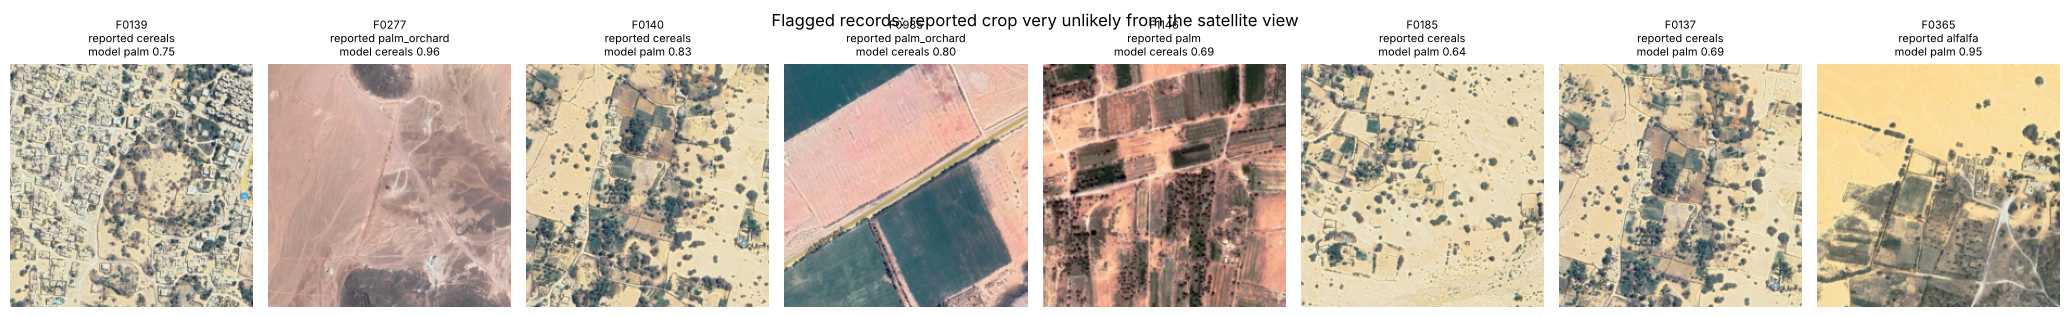

In [22]:
# For each test farm: the model's probability for the crop the farmer reported.
fy, fp = farm_level(TEST, P_tl)
check = pd.DataFrame({"farm": sorted(set(idx.farm.values[TEST])), "reported": [CLASSES[i] for i in fy],
                      "predicted": [CLASSES[i] for i in fp.argmax(1)], "p_reported": fp[np.arange(len(fy)), fy].round(3), "p_predicted": fp.max(1).round(3)})
check["flag"] = (check.p_reported < 0.15) & (check.p_predicted >= 0.6)
print(f"test farms: {len(check)} | flagged for a field check: {check.flag.sum()} ({check.flag.mean():.1%})")
display(check[check.flag].sort_values("p_reported").head(15))
check.to_csv(f"{OUT}/survey_check_test_farms.csv", index=False)

fl = check[check.flag].sort_values("p_reported").head(8)
if len(fl):
    fig, ax = plt.subplots(1, len(fl), figsize=(2.6 * len(fl), 3.2))
    for a, (_, r) in zip(np.atleast_1d(ax), fl.iterrows()):
        i = idx.index[idx.farm == r.farm][0]; a.imshow(X224[580][i]); a.axis("off")
        a.set_title(f"{r.farm}\nreported {r.reported}\nmodel {r.predicted} {r.p_predicted:.2f}", fontsize=8)
    plt.suptitle("Flagged records: reported crop very unlikely from the satellite view"); plt.tight_layout(); plt.savefig(f"{OUT}/flagged_examples.png", dpi=110); plt.show()

## 8. Save models and the inference function

In [23]:
os.makedirs(f"{OUT}/models", exist_ok=True)
cnn.save(f"{OUT}/models/cnn_scratch.keras")
if tl["head"] == "logistic": joblib.dump(head, f"{OUT}/models/transfer_head.joblib")
else: head.save(f"{OUT}/models/transfer_head.keras"); np.savez(f"{OUT}/models/transfer_scaler.npz", mu=mu, sd=sd)
json.dump({"classes": CLASSES, "cnn": {k: list(v) if isinstance(v, tuple) else v for k, v in cnn_cfg.items()}, "transfer": tl}, open(f"{OUT}/models/config.json", "w"), indent=1)

def predict_farm(image_paths, ctx=None):
    """Class probabilities for one farm from one or more 512 x 512 views (transfer model, rotations averaged)."""
    ctx = ctx or tl["ctx"]; m, pre = backbone(tl["backbone"])
    X = np.stack([np.asarray(Image.open(p).convert("RGB").crop((128, 128, 384, 384) if ctx == 290 else (0, 0, 512, 512)).resize((224, 224)), dtype=np.uint8) for p in image_paths])
    R = range(4) if tl["rotations"] else range(1)
    F = np.stack([m.predict(pre(np.rot90(X, r, axes=(1, 2)).astype("float32")), verbose=0) for r in R])
    P = np.mean([head.predict_proba(f) if tl["head"] == "logistic" else head.predict((f - mu) / sd, verbose=0) for f in F], axis=0).mean(0)
    return dict(zip(CLASSES, P.round(3)))

example = idx[idx.split == "test"].farm.iloc[0]
print(example, "reported:", idx.label[idx.farm == example].iloc[0], "->", predict_farm([f"{DATA}/{p}" for p in idx.image[idx.farm == example]]))

F0055 reported: palm -> {'alfalfa': np.float32(0.317), 'cereals': np.float32(0.205), 'palm': np.float32(0.46), 'palm_orchard': np.float32(0.018)}
